## ISOM4030 Lab 6 - Deep Learning with TensorFlow

Before we start...
### Use of GPUs on Colab

The free of charge version of Colab grants access to Nvidia's T4 GPUs subject to quota restrictions and availability. You can request one by doing the following:

Rumtime → Change runtime type → T4 GPU



In [1]:
import tensorflow as tf
print(f"Num GPUs Available: {len(tf.config.list_physical_devices('GPU'))}" )

Num GPUs Available: 1


You can also check GPU utilization with following command:

In [2]:
!nvidia-smi

Sun Oct 12 13:32:41 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8             11W /   70W |       2MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### MNIST Dataset - Classify images of clothing

In [3]:
# Set up the programming environment

# import data munging libraries

import pandas as pd
import numpy as np

# import drawing libraries and configure drawing settings

import matplotlib.pyplot as plt
#plt.style.use('seaborn-white')
%config InlineBackend.figure_format="retina"


# import tensorflow API

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential


# Helper functions for visualizing images

def show_images(image, class_names, num_row=2, num_col=5):
    # plot images
    fig, axes = plt.subplots(num_row, num_col, figsize=(2*num_col, 2*num_row))
    for i in range(num_row*num_col):
        ax = axes[i//num_col, i%num_col]
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        ax.imshow(image[i], cmap=plt.cm.binary)
        ax.set_xlabel(class_names[train_labels[i]])   # show the class name below the image

    plt.tight_layout()
    plt.show()

def visualize_input(img):
    fig, ax = plt.subplots(figsize = (10, 10))
    ax.imshow(img, cmap=plt.cm.binary)
    width, height = img.shape
    thresh = img.max() / 2.5
    for x in range(width):
        for y in range(height):
            ax.annotate(str(round(img[x][y],2)), xy=(y,x),
                        horizontalalignment='center',
                        verticalalignment='center',
                        color='black' if img[x][y]<thresh else 'white')

## Step 1: Explore Your Data

In this lab, we will use the [Fashion MNIST](https://github.com/zalandoresearch/fashion-mnist) dataset which contains 70,000 grayscale images in 10 categories. The images show individual articles of clothing at low resolution (28 by 28 pixels), as seen here:

<table>
  <tr><td>
    <img src="https://tensorflow.org/images/fashion-mnist-sprite.png"
         alt="Fashion MNIST sprite"  width="600">
  </td></tr>
</table>

Here, 60,000 images are used to train the network and 10,000 images to evaluate how accurately the network learned to classify images.

#### Load the Fashion MNIST dataset

In [4]:
fashion_mnist = tf.keras.datasets.fashion_mnist
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Loading the dataset returns four NumPy arrays:

- `train_images`, `train_labels` -- the model uses the *training set* to learn.
- `test_images`, `test_labels` -- and use *test set* to test the model.

The images are 28x28 NumPy arrays, with pixel values ranging from 0 to 255. The *labels* are an array of integers, ranging from 0 to 9. These correspond to the *class* of clothing the image represents:

<table>
  <tr>
    <th>Label</th>
    <th>Class</th>
  </tr>
  <tr>
    <td>0</td>
    <td>T-shirt/top</td>
  </tr>
  <tr>
    <td>1</td>
    <td>Trouser</td>
  </tr>
    <tr>
    <td>2</td>
    <td>Pullover</td>
  </tr>
    <tr>
    <td>3</td>
    <td>Dress</td>
  </tr>
    <tr>
    <td>4</td>
    <td>Coat</td>
  </tr>
    <tr>
    <td>5</td>
    <td>Sandal</td>
  </tr>
    <tr>
    <td>6</td>
    <td>Shirt</td>
  </tr>
    <tr>
    <td>7</td>
    <td>Sneaker</td>
  </tr>
    <tr>
    <td>8</td>
    <td>Bag</td>
  </tr>
    <tr>
    <td>9</td>
    <td>Ankle boot</td>
  </tr>
</table>

Let's take a look at the format of the dataset before training the model.
#### Explore the training set

In [6]:
# explore the training set and training labels

print(f"The shape of training set: {_____________________}")
print(f"The shape of training labels: {_____________________} ")
print(f"There are totally {_____________________} labels in the training set.")

The shape of training set: (60000, 28, 28)
The shape of training labels: (60000,) 
There are totally 60000 labels in the training set.


In [7]:
# explore the testing set and testing labels

print(f"The shape of testing set: {_____________________}" + str())
print(f"The shape of testing labels: {_____________________}")
print(f"There are totally {_____________________} labels in the training set.")

The shape of testing set: (10000, 28, 28)
The shape of testing labels: (10000,)
There are totally 10000 labels in the training set.


Visualize a training image:

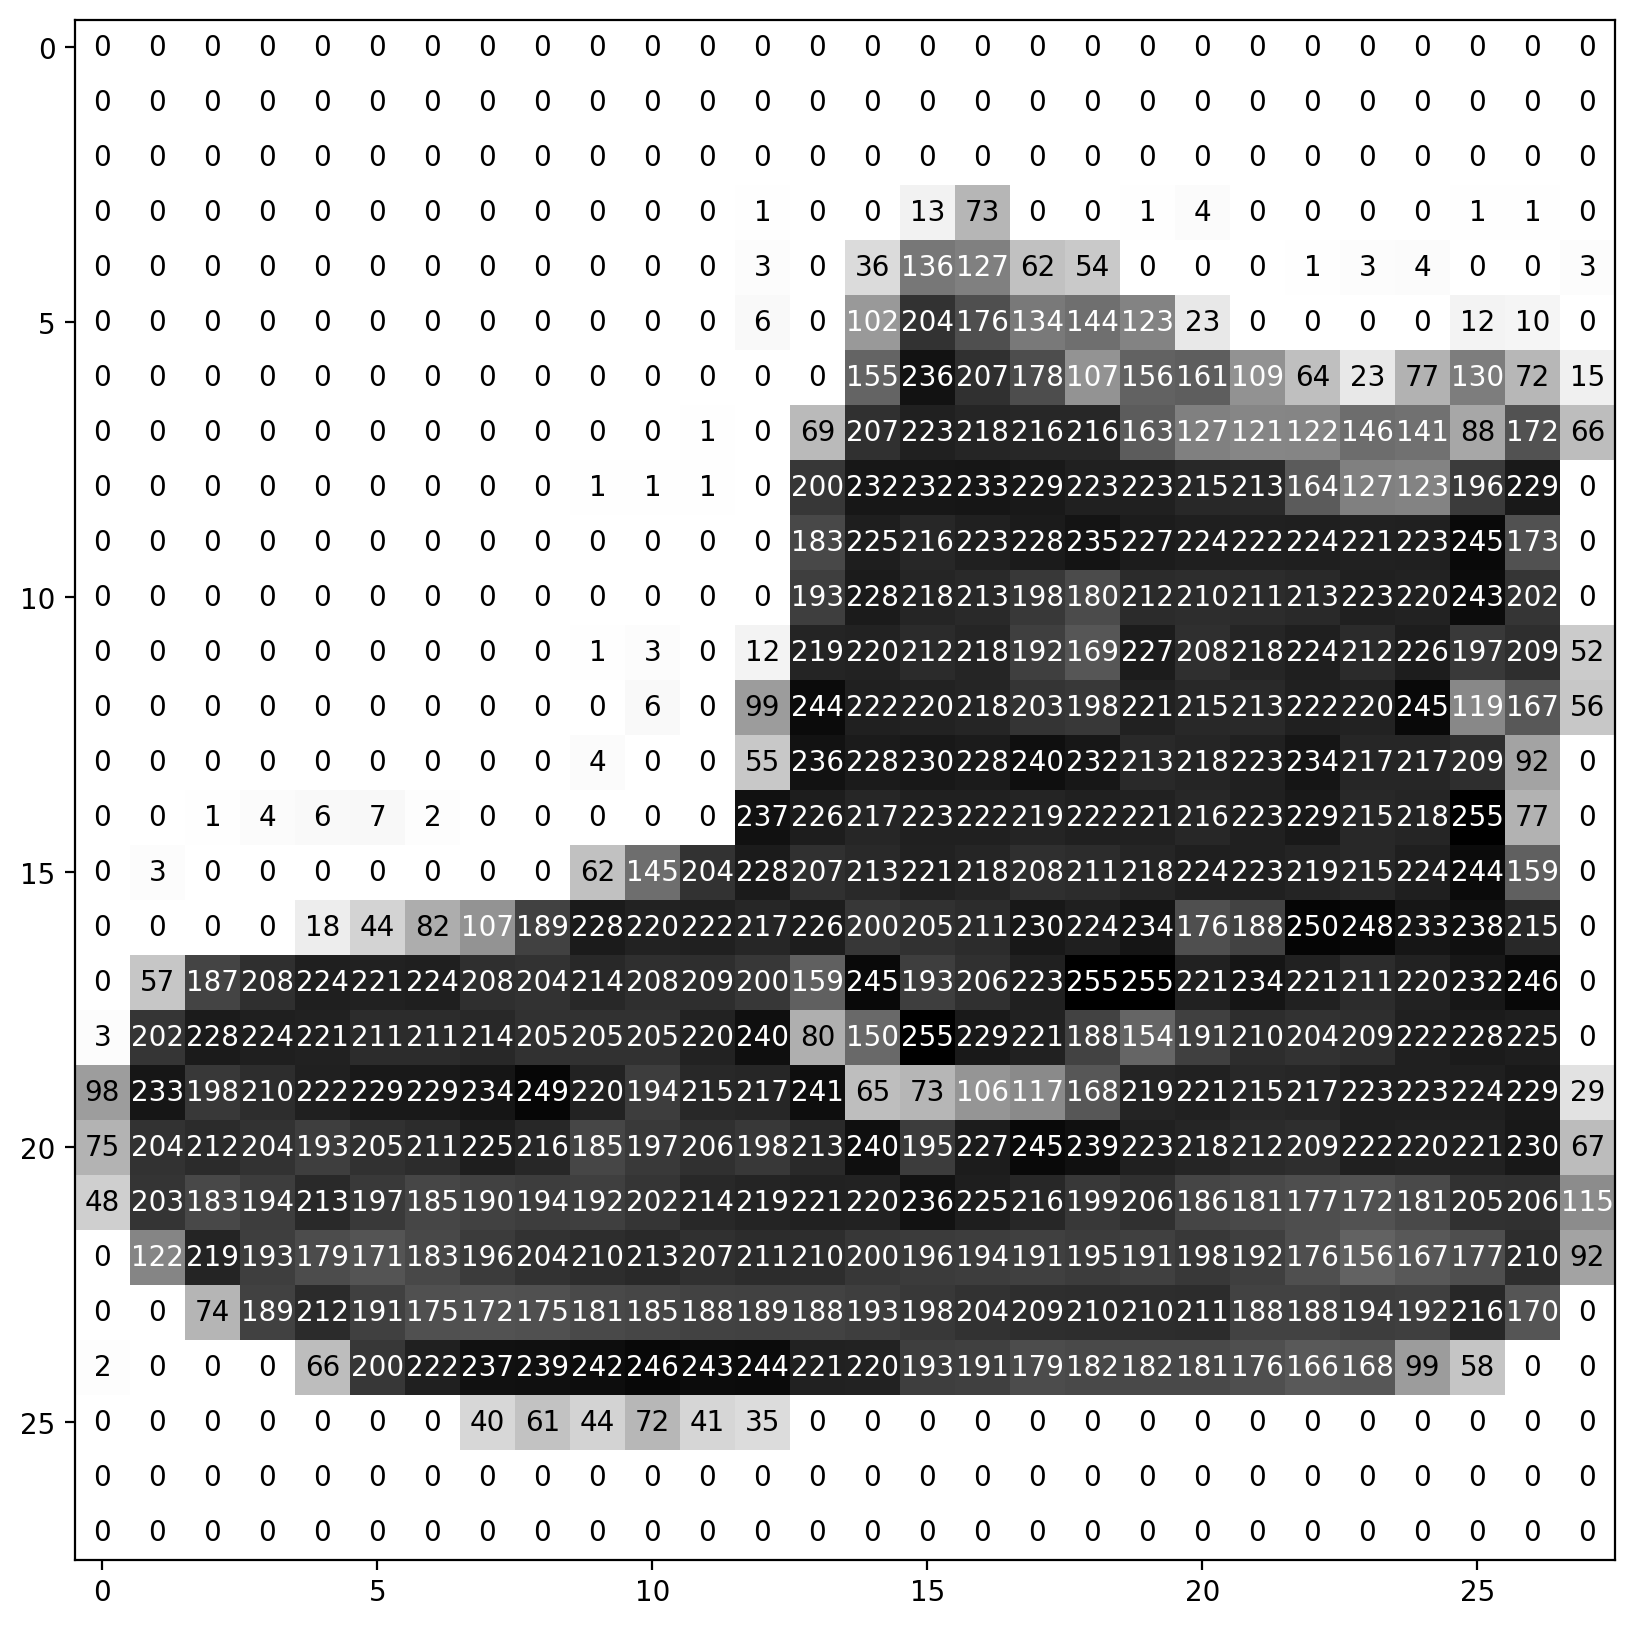

In [8]:
visualize_input(train_images[0])

#### Explore the training labels
The labels are the class IDs, from 0 to 9:

In [9]:
print("The number of occurrences of each label in the training data:\n",
      np.unique(train_labels, return_counts=True))

The number of occurrences of each label in the training data:
 (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8), array([6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000]))


In [10]:
print("Here shows the first 10 training labels:", train_labels[:10])

Here shows the first 10 training labels: [9 0 0 3 0 2 7 2 5 5]


### Step 2: Preprocess the data

In the data preprocessing stage, we scale the pixel intensities down to the 0-1 range by dividing by 255.

In [ ]:
train_images, test_images = train_images/255.0, test_images/255.0

Since the *class names* are not included with the dataset, store them in a list for plotting the images.

In [11]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']



Let's take a look at the first 25 images in the dataset:

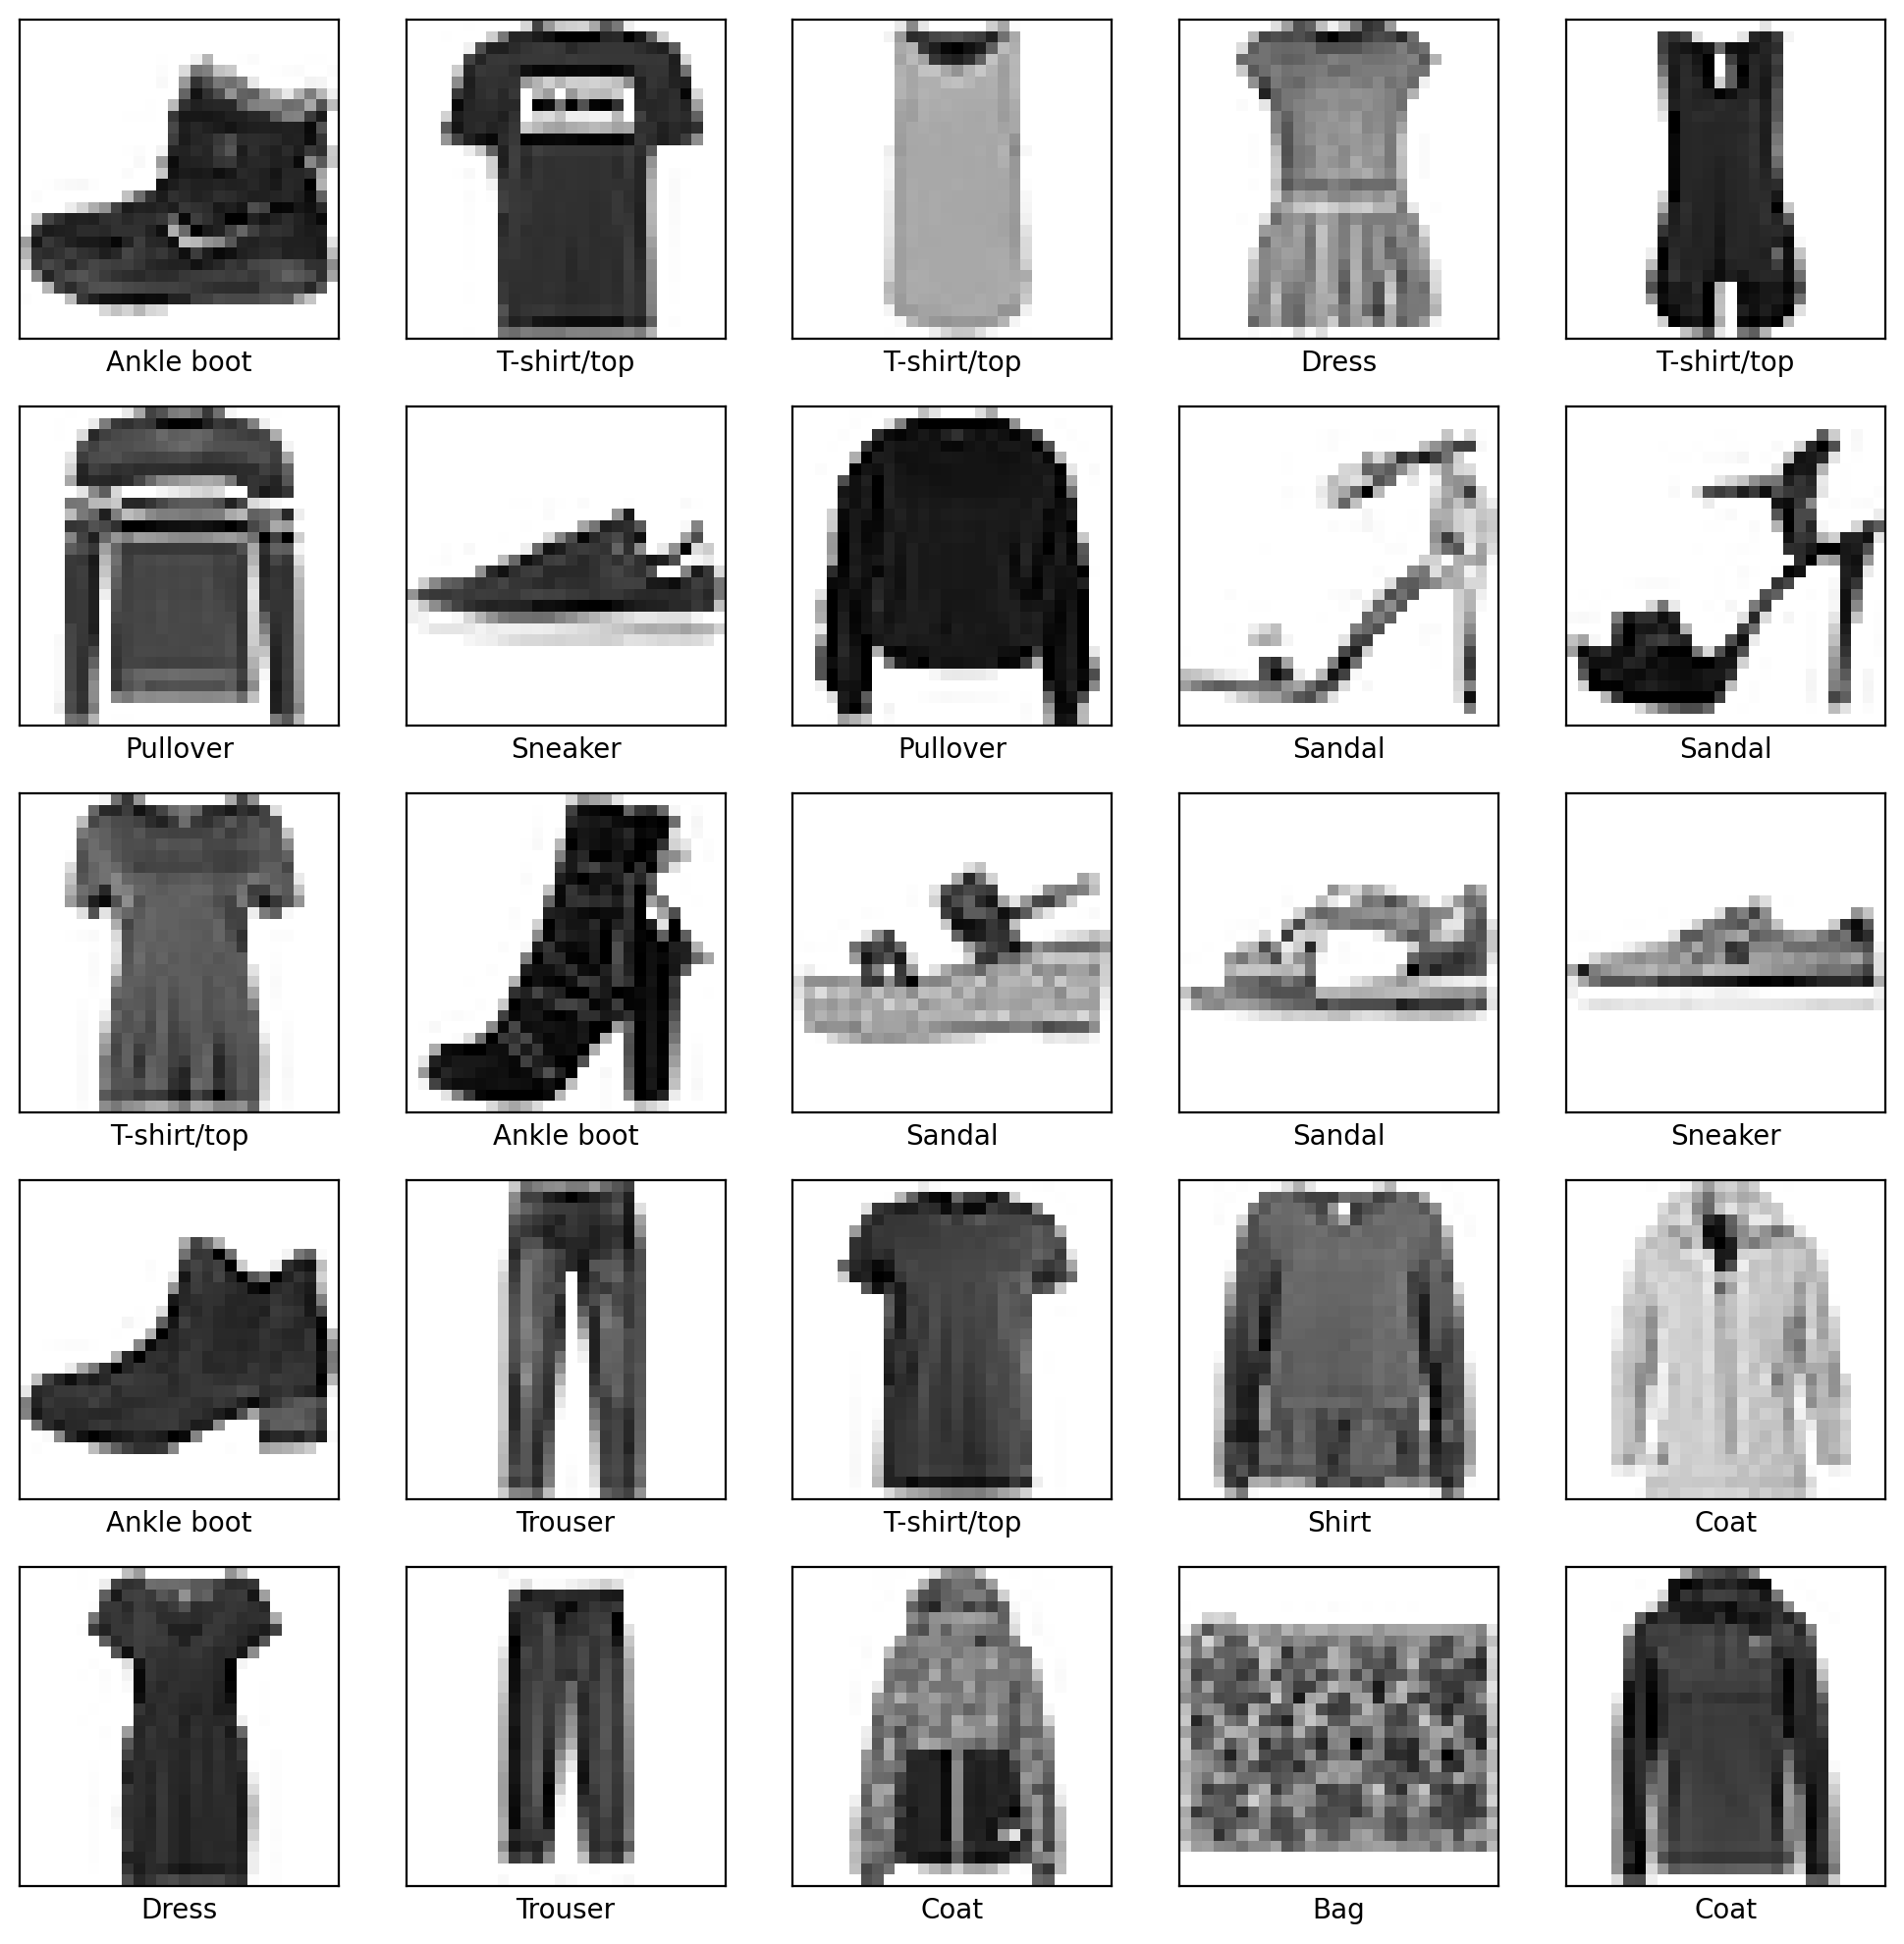

In [12]:
show_images(train_images, class_names, 5, 5)

## Step 3: Build and Train a Neural Network Model



We will build a NN model with 1 hidden layer. The structure is as below:

```Python
              Input (60000 data points, 28 x 28 pixels)
                                ↧
                  [Flatten(input_shape=(28, 28))]
                                ↧
                [Dense(128 units, relu activation)]
                                ↧
                    Output [Dense(10 units)]
```

The first layer in this network, `tf.keras.layers.Flatten`, transforms the format of the images from a two-dimensional array (of 28 by 28 pixels) to a one-dimensional array (of 28 * 28 = 784 pixels). This layer has no parameters to learn; it only reformats the data.

After the pixels are flattened, the network consists of a sequence of two `tf.keras.layers.Dense` layers. These are densely connected, or fully connected, neural layers. The first `Dense` layer has 128 nodes (or neurons). The second (and last) layer returns a logits array with length of 10. Each node contains a score that indicates the current image belongs to one of the 10 classes.



<font color="red"> <b>Questions for thought</b></font> before we go:


- Why do we need the `Flatten()` layer?

> <font color="red"> <b>Answer</b></font>: Our data is 28 by 28  arrays of numbers. But the first hidden layer is a fully connected one, which expects a vector input or a 1-dimensional array. We need to flatten  that 28 by 28 into a vector. Instead of writing all the code to handle that ourselves,
we simply add the `Flatten()` layer, which just takes that square and turns it into a 1-dimensional array.



- Consider the output layer (i.e., the 3rd `Dense()` layer). Why are there 10 neurons? What would happen if you had a number different from 10? What kind of relationships could exist among the outputs of the 10 neurons?

><font color="red"> <b>Answer</b></font>:  This is a multi-class classification problem. The number of neurons in the last layer should match the number of classes we are classifying for. In this case, the classes are the digits 0-9, so there are 10 of them. Therefore, we should have 10 neurons in your final layer.



---
#### Steps:

1) Build the model: stack layers using the [`Sequential`](https://www.tensorflow.org/api_docs/python/tf/keras/Sequential) API . [This is where you specify the number of layers, the number of hidden units within each layer, and the activation function you choose for each layer.]

2) Compile the model: choose the loss function and an optimizer for your model using `.compile()`. [This is where you set the loss function, the optimizer, learning rate, and output metrics]:

* [*Optimizer*](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers) —This is how the model is updated based on the data it sees and its loss function.
* [*Loss function*](https://www.tensorflow.org/api_docs/python/tf/keras/losses) —This measures how accurate the model is during training. You want to minimize this function to "steer" the model in the right direction.
* [*Metrics*](https://www.tensorflow.org/api_docs/python/tf/keras/metrics) —Used to monitor the training and testing steps. The following example uses *accuracy*, the fraction of the images that are correctly classified.

3) Train the model using `.fit()`. [This is where you specify training data, batch size, and number of epochs. This is safer to set a small number of epochs to begin with.]

4) Evaluate the accuracy according to the predicted result.

#### Setup the layers using *Sequential*

In [15]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10)
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


#### Compile the model
#### <font color="red"> <b>Note</b></font>:
-  The loss function we should use for this multi-class classification problem is a cross-entropy loss, which is implemented as the [`keras.losses.SparseCategoricalCrossentropy`](https://www.tensorflow.org/api_docs/python/tf/keras/losses/SparseCategoricalCrossentropy).

- For the optimizer, let's first try the [`keras.optimizers.SGD`](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/SGD) algorithm with the `learning_rate` set to `0.001`.

- We can also specify extra metrics to output.

In [17]:
model.compile(optimizer=keras.optimizers.SGD(learning_rate=0.001),       # can also set it to 'sgd' if you are okay to use the default lr
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

Get a summary of the NN structure. Can you figure out how to calculate the total number of parameters?

In [18]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
# help(model.fit)

#### Train the model
Feed the training data (i.e. `train_images` and `train_labels`) to the model. The model will learn to associate images and labels. As the model trains, the loss and accuracy metrics are displayed. This model reaches an accuracy of about 0.82 (or 82%) on the training data.

One epoch means all data being processed once, which could contain multiple iterations.
In this example, we have 60,000 training samples and the algorithm is going to train 32 per iteration (by default).
So each epoch will go through 60,000/32=1875 iterations!
The total number of iterations is therefore 1875*10.

We assign the test set to the argument value *validation_data* to evaluate the val_loss and val_accruacy by the test set. The model will not be trained on this data.

In [20]:
model_output = model.fit(train_images, train_labels, batch_size=32, epochs=10, validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.4993 - loss: 12.2851 - val_accuracy: 0.6611 - val_loss: 1.1455
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.6892 - loss: 1.0165 - val_accuracy: 0.6788 - val_loss: 0.9022
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.6972 - loss: 0.7931 - val_accuracy: 0.7085 - val_loss: 0.7611
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7173 - loss: 0.7008 - val_accuracy: 0.7203 - val_loss: 0.7207
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7280 - loss: 0.6624 - val_accuracy: 0.7424 - val_loss: 0.6714
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7379 - loss: 0.6523 - val_accuracy: 0.7538 - val_loss: 0.6868
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7526 - loss: 0.6320 - val_accuracy: 0.7630 - val_loss: 0.6734
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7739 - loss: 0.5936 -

#### Evaluate accuracy

Evaluate the model performance by the test dataset:

In [21]:
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)

print('\nTest accuracy:', test_acc)

313/313 - 1s - 2ms/step - accuracy: 0.7325 - loss: 0.6771

Test accuracy: 0.7325000166893005


The loss and accuracy figures are recorded in the *history* attribute.

In [22]:
model_output.history

{'accuracy': [0.5552833080291748,
  0.6899166703224182,
  0.701366662979126,
  0.7176333069801331,
  0.7271999716758728,
  0.7390333414077759,
  0.7602666616439819,
  0.7743833065032959,
  0.781166672706604,
  0.7836166620254517],
 'loss': [3.020066261291504,
  0.952842116355896,
  0.7733891010284424,
  0.7028465270996094,
  0.6703550219535828,
  0.6502920985221863,
  0.6189494132995605,
  0.5963346362113953,
  0.5775660872459412,
  0.5692548155784607],
 'val_accuracy': [0.6610999703407288,
  0.6787999868392944,
  0.7085000276565552,
  0.720300018787384,
  0.7423999905586243,
  0.7537999749183655,
  0.7630000114440918,
  0.8001000285148621,
  0.7821999788284302,
  0.7325000166893005],
 'val_loss': [1.1454983949661255,
  0.9021735191345215,
  0.7610562443733215,
  0.7206754088401794,
  0.6713829636573792,
  0.6868370175361633,
  0.6734437346458435,
  0.5966951847076416,
  0.6632170081138611,
  0.6770555973052979]}

Plot the training accuracy vs. validation accuracy.

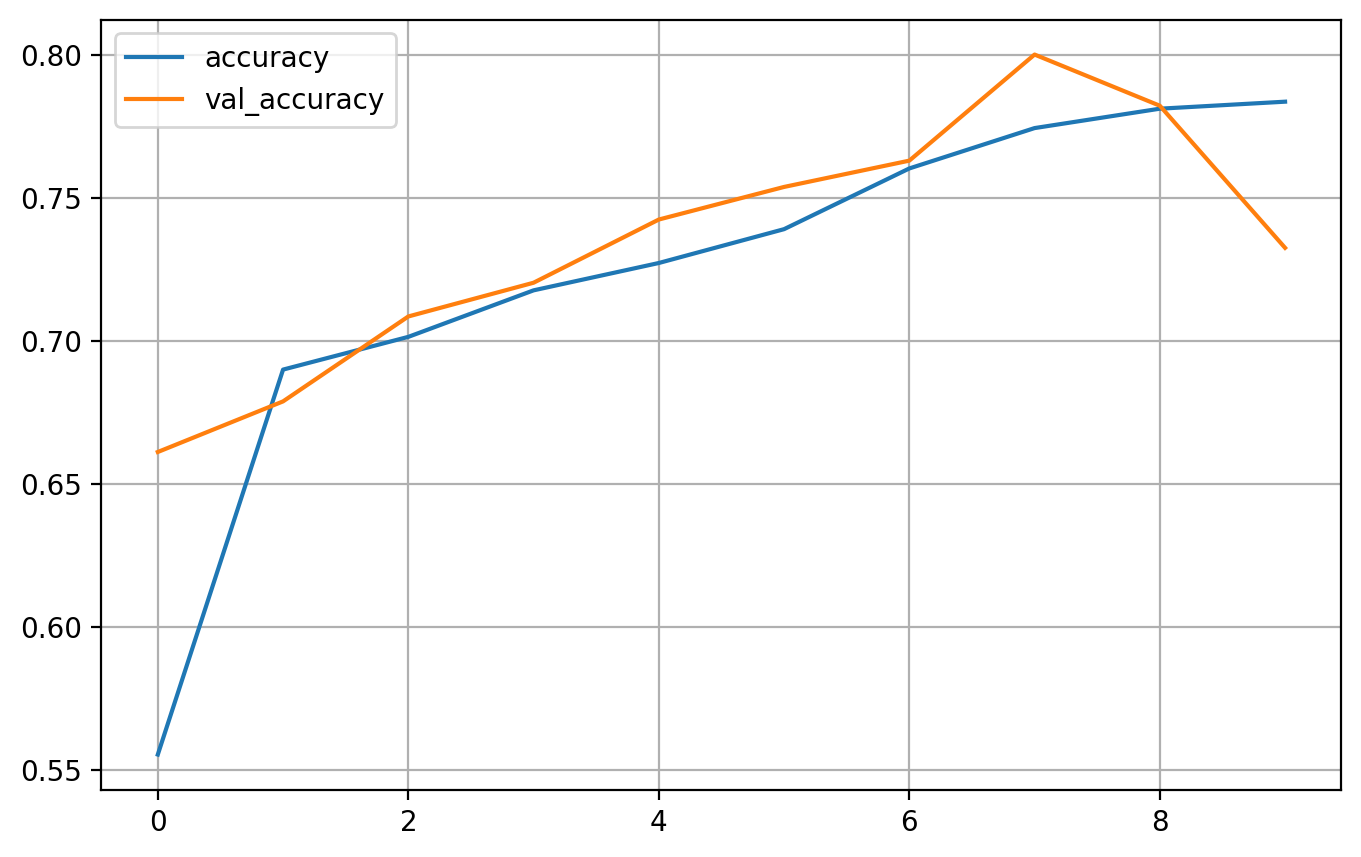

In [23]:
metric_df = pd.DataFrame(model_output.history)
metric_df[['accuracy', 'val_accuracy']].plot(figsize=(8, 5))
plt.grid(True)

#### <font color='steelblue' > Exercise </font>

Defines a neural network model with one hidden layer. The model should:
- consist of a flattening layer, a dense layer with 128 units and ReLU activation function, and a dense output layer with 10 units and softmax activation function.
- be compiled with SGD optimizer, learning rate of 0.003, sparse categorical cross-entropy loss, and accuracy as the evaluation metric.
- be trained using the fit() function with training data (train_images and train_labels), 25 epochs, and a batch size of 32.
- set the test_images and test_labels to be validation data for evaluation of model performance.

Store the training results in the variable 'model_ex_output' for plotting chart.


In [ ]:
# Complete the program below

# Build the model (Define the layers and stack them into a network in order)
model_ex = tf.keras.__________________([


])

# Print a summary of the model structure
print(model_ex.______________())

# Compile the model (Specify the loss function and optimizer to use)
model_ex.________(


)

# Train the model (Specify batch size and number of epochs)
model_ex_output = model_ex._______())

In [ ]:
# plot the accuracy chart
metric_df = pd.DataFrame(model_ex_output.history)
metric_df[['accuracy', 'val_accuracy']].plot(figsize=(8, 5))
plt.grid(True)

## Step 4: Make predictions

With the model trained, you can use it to make predictions about some images.
Attach a softmax layer to convert the model's linear output (logits) to probabilities.

In [ ]:
probability_model = tf.keras.Sequential([model, tf.keras.layers.Softmax()])
probability_model.summary()

In [ ]:
#help(probability_model.predict)

In [ ]:
predictions = probability_model.predict(test_images)  # default batch size = 32

Here, the model has predicted the label for each image in the testing set. Let's take a look at the first prediction:

In [ ]:
predictions[0]

A prediction is an array of 10 numbers. They represent the model's "confidence" that the image corresponds to each of the 10 different articles of clothing. You can see which label has the highest confidence value:

In [ ]:
np.argmax(predictions[0]), np.max(predictions[0])

So, the model is most confident that this image is an ankle boot, or `class_names[9]`. Examining the test label shows that this classification is correct:

In [ ]:
class_names[9]

#### Verify predictions
Define functions to graph the full set of 10 class predictions.

In [ ]:
def plot_image(i, predictions_array, true_label, img):
  true_label, img = true_label[i], img[i]
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])

  plt.imshow(img, cmap=plt.cm.binary)

  predicted_label = np.argmax(predictions_array)
  if predicted_label == true_label:
    color = 'blue'
  else:
    color = 'red'

  plt.xlabel("{} {:2.0f}% ({})".format(class_names[predicted_label],
                                100*np.max(predictions_array),
                                class_names[true_label]),
                                color=color)

def plot_value_array(i, predictions_array, true_label):
  true_label = true_label[i]
  plt.grid(False)
  plt.xticks(range(10))
  plt.yticks([])
  thisplot = plt.bar(range(10), predictions_array, color="#777777")
  plt.ylim([0, 1])
  predicted_label = np.argmax(predictions_array)

  thisplot[predicted_label].set_color('red')
  thisplot[true_label].set_color('blue')

Correct prediction labels are blue and incorrect prediction labels are red. The number gives the percentage (out of 100) for the predicted label.

In [ ]:
i = 0
plt.figure(figsize=(6,3))
plt.subplot(1,2,1)
plot_image(i, predictions[i], test_labels, test_images)
plt.subplot(1,2,2)
plot_value_array(i, predictions[i],  test_labels)
plt.show()

In [ ]:
i = 12
plt.figure(figsize=(6,3))
plt.subplot(1,2,1)
plot_image(i, predictions[i], test_labels, test_images)
plt.subplot(1,2,2)
plot_value_array(i, predictions[i],  test_labels)
plt.show()

Plot 100 images with their predictions.

In [ ]:
# Plot the first 100 test images, their predicted labels, and the true labels.
# Color correct predictions in blue and incorrect predictions in red.
num_rows = 10
num_cols = 10
num_images = num_rows*num_cols
plt.figure(figsize=(2*2*num_cols, 2*num_rows))
for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  plot_image(i, predictions[i], test_labels, test_images)
  plt.subplot(num_rows, 2*num_cols, 2*i+2)
  plot_value_array(i, predictions[i], test_labels)
plt.tight_layout()
plt.show()

### Use the trained model

Finally, use the trained model to make a prediction about a single image.

In [ ]:
# Import the Python Imaging Library
from PIL import Image

# Open the JPG image
image = Image.open("resized_boot.jpg")

# Convert the image to grayscale
gray_image = np.array(image.convert("L"))

# Add the image to a batch where it's the only member.
img = (np.expand_dims(gray_image,0))

print(img.shape)

In [ ]:
predictions_single = probability_model.predict(img)

print(predictions_single)

In [ ]:
plot_value_array(0, predictions_single[0], [9])
_ = plt.xticks(range(10), class_names, rotation=45)
plt.show()

In [ ]:
np.argmax(predictions_single[0])